# Part II — CHS Features and Economic Reasoning

FNCE 2370 — Team 7 | Predicting Corporate Distress Risk

Validate supplied predictors, define common eligibility, screen additional characteristics on initial training coverage, and fit training-only winsorization and imputation parameters.

Run from the repository root (or its `notebooks/` subdirectory). See `README.md` for execution instructions. Source construction conventions are documented following the TA clarification of November 24, 2026; see `README.md` for remaining verification limits.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.6f}".format)

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

file_path = project_root / 'Project_5_data_chs_main_global.parquet'

processed_dir = project_root / "data" / "processed"
tables_dir = project_root / "outputs" / "tables"

panel_path = processed_dir / "part_I_panel.parquet"

assert file_path.exists(), "Raw dataset not found."
assert panel_path.exists(), "Part I panel not found."

print("Input files validated.")

figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

Input files validated.


## Baseline features and economic motivation

Use the eight preferred CHS (2008) predictors, as required by the assignment. The table gives the paper's definitions and expected economic relationships, not constraints on estimated coefficients. Let market-valued total assets (MTA) equal market equity plus book total liabilities.

| Predictor | CHS definition / economic rationale | Expected relation to failure |
|---|---|---|
| `nimtaavg` | Weighted history of net income / MTA; persistent losses weaken financial health | − |
| `tlmta` | Total liabilities / MTA; greater obligations increase risk | + |
| `exretavg` | Weighted history of log excess returns relative to the S&P 500; poor performance signals deterioration | − |
| `sigma` | Annualized zero-centered daily return volatility over three months; equity uncertainty | + |
| `rsize` | Log firm market equity relative to total S&P 500 market equity; financing capacity | Usually − unconditionally; conditional sign may differ |
| `cashmta` | Cash and short-term investments / MTA; liquidity buffer | − |
| `mb` | Market equity / adjusted book equity; valuation and book-equity erosion | Ambiguous (positive in CHS one-month model) |
| `price_log` | Log absolute share price capped at $15; low prices signal distress | − |

CHS uses a two-month accounting lag, quarterly-block weighted NIMTA, monthly weighted EXRET, and a three-month half-life. It adjusts book equity for extreme values and uses a zero-centered volatility calculation. We retain the supplied variables and validate feasible identities and histories below.

**Confirmed source timing (TA clarification, November 24, 2026):** CHS quarterly accounts become eligible two months after fiscal period-end and carry forward until replaced. Six- and twelve-month stale flags are diagnostic, with no age cutoff. The Global Characteristics provider uses a four-month accounting lag, an 18-month maximum age from fiscal period-end and item-specific missing-value rules. The local merge adds no lag and preserves missingness. We impose no second accounting lag or additional age cutoff.

These rules support using supplied features at their assigned month-end. They are not an independent verification of individual accounting release dates, restatements, underlying daily returns or book-equity adjustments. The supplementary schema/metadata diagnostics do not expose the original accounting release or fiscal-period fields; the TA's clarification establishes the construction conventions rather than a reconstruction from the raw source records.

In [2]:
CHS_FEATURES = [
    "nimtaavg",
    "tlmta",
    "exretavg",
    "sigma",
    "rsize",
    "cashmta",
    "mb",
    "price_log"
]

AUXILIARY_FEATURES = [
    "nimta",
    "nita",
    "tlta",
    "exret",
    "sigma_fill",
    "prc",
    "market_equity",
    "ret_adj",
    "sprtrn"
]

KEYS = ["permno", "month_end"]

print("Number of CHS predictors:", len(CHS_FEATURES))
print("Number of auxiliary variables:", len(AUXILIARY_FEATURES))

Number of CHS predictors: 8
Number of auxiliary variables: 9


In [3]:
panel = pd.read_parquet(panel_path)

features = pd.read_parquet(
    file_path,
    columns=KEYS + CHS_FEATURES + AUXILIARY_FEATURES
)

features["month_end"] = pd.to_datetime(
    features["month_end"]
)

assert not features.duplicated(KEYS).any()
assert not panel.duplicated(KEYS).any()

df = panel.merge(
    features,
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(df) == len(panel)
assert df["_merge"].eq("both").all()

df = df.drop(columns="_merge")

df = df.sort_values(
    ["permno", "feature_month"]
).reset_index(drop=True)

del features, panel

print("Dataset shape:", df.shape)
print("Labeled observations:", df["labeled"].sum())

print(
    "Memory usage (GB):",
    round(df.memory_usage(deep=True).sum() / 1e9, 3)
)

Dataset shape: (3416761, 27)
Labeled observations: 3415782
Memory usage (GB): 0.837


## Development-only diagnostics

Use forecast-month cutoffs (Part III) before estimating any transformation or screening characteristics. Initial training ends in December 1995; validation covers 1996–2003. Distributional and failure-group diagnostics are based on training data, with validation coverage used descriptively. The final 2004–2024 period is not used to select features or estimate preprocessing parameters.

In [4]:
TRAIN_END = pd.Timestamp("1995-12-31")
VALIDATION_END = pd.Timestamp("2003-12-31")
TEST_END = pd.Timestamp("2024-12-31")

train_mask = (
    df["labeled"]
    & df["forecast_month"].le(TRAIN_END)
)

validation_mask = (
    df["labeled"]
    & df["forecast_month"].gt(TRAIN_END)
    & df["forecast_month"].le(VALIDATION_END)
)

development_mask = train_mask | validation_mask

print("Initial training observations:", train_mask.sum())
print("Validation observations:", validation_mask.sum())
print("Development observations:", development_mask.sum())

Initial training observations: 1774654
Validation observations: 620641
Development observations: 2395295


In [5]:
train_features = df.loc[
    train_mask,
    CHS_FEATURES
].replace([np.inf, -np.inf], np.nan)

feature_summary = train_features.describe(
    percentiles=[
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99
    ]
).T

feature_summary["missing_pct"] = (
    train_features.isna().mean() * 100
)

display(feature_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,missing_pct
nimtaavg,1695487.000000,0.001693,0.033519,-5.117984,-0.102774,-0.032584,0.000168,0.006436,0.011874,0.020820,0.034024,3.764498,4.460982
tlmta,1053901.000000,0.455656,0.273559,-1.156963,0.011214,0.046528,0.220515,0.446326,0.670480,0.922602,0.970545,0.999779,40.613720
exretavg,1752879.000000,-0.004892,0.051451,-1.142616,-0.164332,-0.089155,-0.027167,-0.001686,0.021579,0.068881,0.121932,0.667715,1.227000
sigma,1708151.000000,0.520583,0.414837,0.015000,0.099975,0.155844,0.276976,0.420266,0.633786,1.205318,2.027953,34.859493,3.747378
rsize,1757208.000000,-10.201360,1.981842,-19.523738,-14.312711,-13.220390,-11.614169,-10.351153,-8.897835,-6.692372,-5.419907,-2.243199,0.983065
cashmta,1042065.000000,0.089304,0.138464,-0.174582,0.000067,0.002121,0.015271,0.044588,0.111464,0.313579,0.628470,10.091864,41.280667
mb,1151206.000000,3.554845,97.185847,0.003080,0.251227,0.443632,0.836773,1.306567,2.187726,5.102557,13.553900,76075.000000,35.130679
price_log,1757305.000000,1.957242,1.037141,-4.158563,-1.760959,-0.207639,1.504077,2.442347,2.708050,2.708050,2.708050,2.708050,0.977599


In [6]:
missingness = pd.DataFrame({
    "training_missing_pct":
        df.loc[train_mask, CHS_FEATURES]
        .isna().mean() * 100,

    "validation_missing_pct":
        df.loc[validation_mask, CHS_FEATURES]
        .isna().mean() * 100,

    "training_nonfailure_missing_pct":
        df.loc[
            train_mask & df["target"].eq(0),
            CHS_FEATURES
        ].isna().mean() * 100,

    "training_failure_missing_pct":
        df.loc[
            train_mask & df["target"].eq(1),
            CHS_FEATURES
        ].isna().mean() * 100
})

display(missingness)

,training_missing_pct,validation_missing_pct,training_nonfailure_missing_pct,training_failure_missing_pct
nimtaavg,4.460982,0.000000,4.466415,1.238701
tlmta,40.613720,4.153770,40.638619,25.845330
exretavg,1.227000,0.000000,1.228278,0.468698
sigma,3.747378,0.233146,3.722822,18.312688
rsize,0.983065,0.054138,0.982803,1.138266
cashmta,41.280667,4.273002,41.306239,26.113157
mb,35.130679,4.145069,35.148140,24.774021
price_log,0.977599,0.054138,0.977385,1.104787


In [7]:
train = df.loc[train_mask]

unusual_values = pd.Series({
    "Negative TLMTA":
        train["tlmta"].lt(0).sum(),

    "TLMTA above one":
        train["tlmta"].gt(1).sum(),

    "Negative CASHMTA":
        train["cashmta"].lt(0).sum(),

    "CASHMTA above one":
        train["cashmta"].gt(1).sum(),

    "Nonpositive MB":
        train["mb"].le(0).sum(),

    "Nonpositive SIGMA":
        train["sigma"].le(0).sum(),

    "SIGMA above five":
        train["sigma"].gt(5).sum(),

    "PRICE above log(15)":
        train["price_log"].gt(
            np.log(15) + 1e-6
        ).sum(),

    "Infinite CHS values":
        np.isinf(
            train[CHS_FEATURES]
            .to_numpy(dtype=float)
        ).sum()
})

display(unusual_values)

Negative TLMTA           15
TLMTA above one           0
Negative CASHMTA       1926
CASHMTA above one      2726
Nonpositive MB            0
Nonpositive SIGMA         0
SIGMA above five        904
PRICE above log(15)       0
Infinite CHS values       0
dtype: int64

## Validate supplied feature construction

Test PRICE against the supplied share price and EXRET against log gross returns minus log gross S&P 500 returns. The accounting-ratio identity below checks consistency of shared numerators and denominators, not the original accounting release dates. The TA confirms supplied `sigma_fill` uses the same-month cross-sectional mean. Use raw `sigma` rather than `sigma_fill` so our alternative imputation rule is explicitly estimated on the eligible training sample.

In [8]:
valid_price = (
    train["prc"].notna()
    & train["prc"].ne(0)
    & train["price_log"].notna()
)

expected_price = np.log(
    train.loc[valid_price, "prc"]
    .abs()
    .clip(upper=15)
)

price_error = (
    train.loc[valid_price, "price_log"]
    - expected_price
).abs()

price_validation = pd.Series({
    "Comparable observations": len(price_error),

    "Matching observations":
        price_error.le(1e-6).sum(),

    "Mismatched observations":
        price_error.gt(1e-6).sum(),

    "Mean absolute error": price_error.mean(),

    "Maximum absolute error": price_error.max()
})

display(price_validation)

Comparable observations   1757305.000000
Matching observations     1730269.000000
Mismatched observations     27036.000000
Mean absolute error             0.000000
Maximum absolute error          0.000320
dtype: float64

In [9]:
valid_returns = (
    train["ret_adj"].gt(-1)
    & train["sprtrn"].gt(-1)
    & train["exret"].notna()
)

expected_exret = (
    np.log1p(train.loc[valid_returns, "ret_adj"])
    - np.log1p(train.loc[valid_returns, "sprtrn"])
)

exret_error = (
    train.loc[valid_returns, "exret"]
    - expected_exret
).abs()

exret_validation = pd.Series({
    "Comparable observations": len(exret_error),

    "Matching observations":
        exret_error.le(1e-6).sum(),

    "Mismatched observations":
        exret_error.gt(1e-6).sum(),

    "Mean absolute error": exret_error.mean(),

    "Maximum absolute error": exret_error.max()
})

display(exret_validation)

Comparable observations   1741131.000000
Matching observations     1741131.000000
Mismatched observations         0.000000
Mean absolute error             0.000000
Maximum absolute error          0.000000
dtype: float64

In [10]:
observed_sigma = train["sigma"].notna()

sigma_difference = (
    train.loc[observed_sigma, "sigma"]
    - train.loc[observed_sigma, "sigma_fill"]
).abs()

sigma_diagnostics = pd.Series({
    "Observed SIGMA":
        train["sigma"].notna().sum(),

    "Missing SIGMA":
        train["sigma"].isna().sum(),

    "Missing SIGMA_FILL":
        train["sigma_fill"].isna().sum(),

    "Missing SIGMA replaced by SIGMA_FILL":
        (
            train["sigma"].isna()
            & train["sigma_fill"].notna()
        ).sum(),

    "Observed SIGMA altered by SIGMA_FILL":
        sigma_difference.gt(1e-6).sum()
})

display(sigma_diagnostics)

imputed_sigma = train.loc[
    train["sigma"].isna()
    & train["sigma_fill"].notna(),
    ["feature_month", "sigma_fill"]
]

display(imputed_sigma["sigma_fill"].describe())

Observed SIGMA                          1708151
Missing SIGMA                             66503
Missing SIGMA_FILL                            0
Missing SIGMA replaced by SIGMA_FILL      66503
Observed SIGMA altered by SIGMA_FILL          0
dtype: int64

count   66503.000000
mean        0.510628
std         0.111065
min         0.329063
25%         0.431740
50%         0.484422
75%         0.552351
max         0.929601
Name: sigma_fill, dtype: float64

In [11]:
monthly_sigma_mean = train.groupby(
    "feature_month"
)["sigma"].mean()

expected_fill = imputed_sigma[
    "feature_month"
].map(monthly_sigma_mean)

fill_error = (
    imputed_sigma["sigma_fill"] - expected_fill
).abs()

display(fill_error.describe())

print(
    "Share matching monthly cross-sectional mean:",
    f"{fill_error.le(1e-6).mean():.4%}"
)

count   66503.000000
mean        0.002391
std         0.002452
min         0.000000
25%         0.000768
50%         0.001401
75%         0.003449
max         0.018909
dtype: float64

Share matching monthly cross-sectional mean: 0.0075%


In [12]:
accounting_diagnostics = pd.Series({
    "Missing current NIMTA":
        train["nimta"].isna().sum(),

    "Missing NIMTAAVG":
        train["nimtaavg"].isna().sum(),

    "Missing NIMTA with available NIMTAAVG":
        (
            train["nimta"].isna()
            & train["nimtaavg"].notna()
        ).sum(),

    "Missing all three accounting ratios":
        train[
            ["tlmta", "cashmta", "mb"]
        ].isna().all(axis=1).sum(),

    "Complete CHS observations":
        train_features.notna().all(axis=1).sum()
})

display(accounting_diagnostics)

Missing current NIMTA                     724434
Missing NIMTAAVG                           79167
Missing NIMTA with available NIMTAAVG     645278
Missing all three accounting ratios       623412
Complete CHS observations                1022396
dtype: int64

In [13]:
group_means = (
    train.groupby("target")[CHS_FEATURES]
    .mean()
    .T
)

group_means.columns = [
    "Non-failure",
    "Failure"
]

group_means["Difference"] = (
    group_means["Failure"]
    - group_means["Non-failure"]
)

display(group_means)

,Non-failure,Failure,Difference
nimtaavg,0.001826,-0.074662,-0.076489
tlmta,0.455320,0.615298,0.159979
exretavg,-0.004692,-0.122289,-0.117597
sigma,0.518744,1.806760,1.288017
rsize,-10.195561,-13.646321,-3.450760
cashmta,0.089338,0.073373,-0.015965
mb,3.547363,7.380402,3.833039
price_log,1.961993,-0.864821,-2.826814


In [14]:
group_medians = (
    train.groupby("target")[CHS_FEATURES]
    .median()
    .T
)

group_medians.columns = [
    "Non-failure",
    "Failure"
]

group_medians["Difference"] = (
    group_medians["Failure"]
    - group_medians["Non-failure"]
)

display(group_medians)

,Non-failure,Failure,Difference
nimtaavg,0.006468,-0.037609,-0.044077
tlmta,0.445992,0.680851,0.234859
exretavg,-0.001630,-0.102954,-0.101323
sigma,0.419849,1.407098,0.987250
rsize,-10.347140,-13.741389,-3.394250
cashmta,0.044637,0.022216,-0.022421
mb,1.306050,1.822000,0.515950
price_log,2.442347,-0.900787,-3.343134


In [15]:
valid_accounting = (
    train["nimta"].notna()
    & train["nita"].notna()
    & train["tlta"].gt(0)
    & train["tlmta"].notna()
)

expected_nimta = (
    train.loc[valid_accounting, "nita"]
    * train.loc[valid_accounting, "tlmta"]
    / train.loc[valid_accounting, "tlta"]
)

nimta_error = (
    train.loc[valid_accounting, "nimta"]
    - expected_nimta
).abs()

accounting_validation = pd.Series({
    "Comparable observations": len(nimta_error),
    "Matches within 1e-6": nimta_error.le(1e-6).sum(),
    "Matches within 1e-4": nimta_error.le(1e-4).sum(),
    "Mean absolute error": nimta_error.mean(),
    "Median absolute error": nimta_error.median(),
    "99th percentile error": nimta_error.quantile(0.99),
    "Maximum absolute error": nimta_error.max()
})

display(accounting_validation)

Comparable observations   1050102.000000
Matches within 1e-6       1050102.000000
Matches within 1e-4       1050102.000000
Mean absolute error             0.000000
Median absolute error           0.000000
99th percentile error           0.000000
Maximum absolute error          0.000000
dtype: float64

## Rolling and weighted features

Use the unrestricted historical security panel before eligibility screens so removed observations do not create artificial return gaps. Validate complete consecutive histories using current and past feature-month observations only. The monthly weights are proportional to $\phi^j$ for $j=0,\ldots,11$, with $\phi=2^{-1/3}$ (a three-month half-life). Compare the original CHS quarterly-block NIMTA convention with the supplied series; incomplete-history treatment is not established by these tests. The TA confirmed that missing monthly inputs to both NIMTAAVG and EXRETAVG are replaced by the cross-sectional mean for the same historical month before weighting. Retain the supplied weighted series.

In [16]:
history = pd.read_parquet(
    file_path,
    columns=[
        "permno",
        "month_end",
        "exret",
        "exretavg",
        "nimta",
        "nimtaavg"
    ]
)

history["month_end"] = pd.to_datetime(
    history["month_end"]
)

# Use only information preceding the training cutoff
history = history.loc[
    history["month_end"] < TRAIN_END
].copy()

history = history.sort_values(
    ["permno", "month_end"]
).reset_index(drop=True)

phi = 2 ** (-1 / 3)

weights = phi ** np.arange(12)
weights = weights / weights.sum()

weight_table = pd.DataFrame({
    "lag_month": np.arange(12),
    "weight": weights
})

display(weight_table)
print("Sum of weights:", weights.sum())

,lag_month,weight
0,0,0.220053
1,1,0.174656
2,2,0.138625
3,3,0.110026
4,4,0.087328
5,5,0.069312
6,6,0.055013
7,7,0.043664
8,8,0.034656
9,9,0.027507


Sum of weights: 1.0


In [17]:
history["month_index"] = (
    history["month_end"].dt.year * 12
    + history["month_end"].dt.month
)

groups = history.groupby("permno", sort=False)

weighted_exret = np.zeros(len(history))
valid_history = np.ones(len(history), dtype=bool)

for lag, weight in enumerate(weights):

    lagged_return = groups["exret"].shift(lag)
    lagged_month = groups["month_index"].shift(lag)

    consecutive = (
        history["month_index"] - lagged_month
    ).eq(lag)

    valid_history &= (
        lagged_return.notna() & consecutive
    ).to_numpy()

    weighted_exret += (
        weight * lagged_return.fillna(0).to_numpy()
    )

history["exretavg_reconstructed"] = np.where(
    valid_history,
    weighted_exret,
    np.nan
)

comparable = (
    history["exretavg_reconstructed"].notna()
    & history["exretavg"].notna()
)

exretavg_error = (
    history.loc[comparable, "exretavg"]
    - history.loc[comparable, "exretavg_reconstructed"]
).abs()

exretavg_validation = pd.Series({
    "Comparable observations": comparable.sum(),
    "Matches within 1e-6": exretavg_error.le(1e-6).sum(),
    "Matches within 1e-4": exretavg_error.le(1e-4).sum(),
    "Mean absolute error": exretavg_error.mean(),
    "Median absolute error": exretavg_error.median(),
    "99th percentile error": exretavg_error.quantile(0.99),
    "Maximum absolute error": exretavg_error.max()
})

display(exretavg_validation)

Comparable observations   1535215.000000
Matches within 1e-6       1535215.000000
Matches within 1e-4       1535215.000000
Mean absolute error             0.000000
Median absolute error           0.000000
99th percentile error           0.000000
Maximum absolute error          0.000000
dtype: float64

In [18]:
quarter_weights = phi ** (3 * np.arange(4))
quarter_weights /= quarter_weights.sum()

display(pd.DataFrame({
    "quarter_lag": np.arange(4),
    "weight": quarter_weights
}))

,quarter_lag,weight
0,0,0.533333
1,1,0.266667
2,2,0.133333
3,3,0.066667


In [19]:
monthly_weights = np.repeat(
    quarter_weights / 3,
    3
)

weighted_nimta = np.zeros(len(history))
valid_nimta_history = np.ones(
    len(history),
    dtype=bool
)

for lag, weight in enumerate(monthly_weights):

    lagged_nimta = groups["nimta"].shift(lag)
    lagged_month = groups["month_index"].shift(lag)

    consecutive = (
        history["month_index"] - lagged_month
    ).eq(lag)

    valid_nimta_history &= (
        lagged_nimta.notna() & consecutive
    ).to_numpy()

    weighted_nimta += (
        weight * lagged_nimta.fillna(0).to_numpy()
    )

history["nimtaavg_reconstructed"] = np.where(
    valid_nimta_history,
    weighted_nimta,
    np.nan
)

comparable = (
    history["nimtaavg_reconstructed"].notna()
    & history["nimtaavg"].notna()
)

nimtaavg_error = (
    history.loc[comparable, "nimtaavg"]
    - history.loc[comparable, "nimtaavg_reconstructed"]
).abs()

nimtaavg_validation = pd.Series({
    "Comparable observations": comparable.sum(),
    "Matches within 1e-6": nimtaavg_error.le(1e-6).sum(),
    "Matches within 1e-4": nimtaavg_error.le(1e-4).sum(),
    "Mean absolute error": nimtaavg_error.mean(),
    "Median absolute error": nimtaavg_error.median(),
    "99th percentile error": nimtaavg_error.quantile(0.99),
    "Maximum absolute error": nimtaavg_error.max()
})

display(nimtaavg_validation)

del history, groups

Comparable observations   869404.000000
Matches within 1e-6        25432.000000
Matches within 1e-4       416569.000000
Mean absolute error            0.000502
Median absolute error          0.000110
99th percentile error          0.006277
Maximum absolute error         0.428848
dtype: float64

## Baseline eligibility and missing values

Require finite values for all seven non-SIGMA CHS predictors, including `nimtaavg` and `exretavg`; do not invent missing accounting ratios. Allow missing raw SIGMA and later impute it using the winsorized estimation-sample mean, rather than the paper's and supplied `sigma_fill` same-month cross-sectional mean. This is our downstream preprocessing choice, not a claim that the supplied method is invalid. In the original training run this retained 432 additional positive outcomes relative to complete-case deletion (2,207 versus 1,775). The restriction reduces early accounting coverage substantially; use the same eligible rows for baseline and expanded model comparisons, and treat broader imputation as a possible robustness exercise.

In [20]:
CHS_REQUIRED = [
    feature for feature in CHS_FEATURES
    if feature != "sigma"
]

finite_chs = (
    df[CHS_FEATURES]
    .replace([np.inf, -np.inf], np.nan)
)

df["baseline_eligible"] = (
    finite_chs[CHS_REQUIRED]
    .notna()
    .all(axis=1)
)

print(
    "Baseline-eligible forecasting observations:",
    df["baseline_eligible"].sum()
)

print(
    "Baseline-eligible labeled observations:",
    (
        df["baseline_eligible"]
        & df["labeled"]
    ).sum()
)

Baseline-eligible forecasting observations: 2623210
Baseline-eligible labeled observations: 2623095


In [21]:
sample_policies = {
    "Unrestricted": pd.Series(True, index=df.index),

    "Complete case":
        finite_chs.notna().all(axis=1),

    "Selective SIGMA imputation":
        df["baseline_eligible"]
}

period_masks = {
    "Training": train_mask,
    "Validation": validation_mask
}

records = []

for period, period_mask in period_masks.items():

    original = df.loc[period_mask]

    for policy, policy_mask in sample_policies.items():

        sample = df.loc[period_mask & policy_mask]

        records.append({
            "period": period,
            "policy": policy,
            "observations": len(sample),
            "unique_securities": sample["permno"].nunique(),
            "failures": sample["target"].sum(),
            "failure_rate_pct": sample["target"].mean() * 100,

            "observations_retained_pct":
                len(sample) / len(original) * 100,

            "failures_retained_pct":
                sample["target"].sum()
                / original["target"].sum() * 100
        })

policy_comparison = pd.DataFrame(records)

display(policy_comparison)

,period,policy,observations,unique_securities,failures,failure_rate_pct,observations_retained_pct,failures_retained_pct
0,Training,Unrestricted,1774654,17174,2987,0.168314,100.000000,100.000000
1,Training,Complete case,1022396,12813,1775,0.173612,57.611005,59.424171
2,Training,Selective SIGMA imputation,1042054,12847,2207,0.211793,58.718714,73.886843
3,Validation,Unrestricted,620641,10887,1981,0.319186,100.000000,100.000000
4,Validation,Complete case,594037,10624,1924,0.323886,95.713464,97.122665
5,Validation,Selective SIGMA imputation,594121,10624,1925,0.324008,95.726998,97.173145


## Expanded information set

Start with an explicit economically motivated 39-characteristic candidate list rather than all numeric columns. Profitability and liquidity measure internal funding and cash buffers; leverage measures obligations; growth and investment capture deterioration or excessive expansion; size and age proxy for financing access and maturity. Valuation and momentum capture market expectations, volatility captures uncertainty, issuance measures external financing or recapitalization, asset tangibility captures collateral, and trading liquidity reflects market frictions. These are economic motivations, not causal claims or verified vendor definitions. Exclude metadata, future returns and composite distress scores from this initial library.

In [22]:
FEATURE_GROUPS = {
    "profitability": [
        "gp_at",
        "op_at",
        "niq_at",
        "ebit_sale",
        "ocf_at"
    ],

    "leverage": [
        "at_be",
        "debt_me",
        "netdebt_me"
    ],

    "liquidity": [
        "cash_at",
        "aliq_at",
        "aliq_mat"
    ],

    "growth": [
        "at_gr1",
        "sale_gr1",
        "saleq_gr1",
        "niq_at_chg1"
    ],

    "investment": [
        "capx_gr1",
        "inv_gr1",
        "noa_gr1a"
    ],

    "size": [
        "me_company"
    ],

    "valuation": [
        "be_me",
        "ni_me",
        "ocf_me",
        "ebitda_mev"
    ],

    "momentum": [
        "ret_1_0",
        "ret_6_1",
        "ret_12_1"
    ],

    "volatility": [
        "rvol_21d",
        "ivol_capm_252d",
        "earnings_variability"
    ],

    "issuance": [
        "chcsho_12m",
        "eqnetis_at",
        "dbnetis_at"
    ],

    "intangible_capital": [
        "rd_sale",
        "rd5_at",
        "tangibility"
    ],

    "trading_liquidity": [
        "ami_126d",
        "zero_trades_126d",
        "turnover_126d"
    ],

    "firm_maturity": [
        "age"
    ]
}

GLOBAL_FEATURES = [
    feature
    for features in FEATURE_GROUPS.values()
    for feature in features
]

ALL_FEATURES = CHS_FEATURES + GLOBAL_FEATURES

available_columns = pq.ParquetFile(
    file_path
).schema_arrow.names

missing_columns = [
    col for col in ALL_FEATURES
    if col not in available_columns
]

assert not missing_columns, missing_columns

print("CHS predictors:", len(CHS_FEATURES))
print("Global characteristics:", len(GLOBAL_FEATURES))
print("Total predictors:", len(ALL_FEATURES))

CHS predictors: 8
Global characteristics: 39
Total predictors: 47


In [23]:
import gc

del train, train_features, finite_chs

gc.collect()

32

In [24]:
global_features = pd.read_parquet(
    file_path,
    columns=KEYS + GLOBAL_FEATURES
)

global_features["month_end"] = pd.to_datetime(
    global_features["month_end"]
)

assert not global_features.duplicated(KEYS).any()

original_rows = len(df)

df = df.merge(
    global_features,
    on=KEYS,
    how="left",
    validate="one_to_one",
    sort=False,
    indicator=True
)

assert len(df) == original_rows
assert df["_merge"].eq("both").all()

df = df.drop(columns="_merge")

del global_features
gc.collect()

# Reconstruct masks following merge
train_mask = (
    df["labeled"]
    & df["forecast_month"].le(TRAIN_END)
)

validation_mask = (
    df["labeled"]
    & df["forecast_month"].gt(TRAIN_END)
    & df["forecast_month"].le(VALIDATION_END)
)

development_mask = train_mask | validation_mask

print("Dataset shape:", df.shape)

print(
    "Memory usage (GB):",
    round(df.memory_usage(deep=True).sum() / 1e9, 3)
)

Dataset shape: (3416761, 67)
Memory usage (GB): 1.906


In [25]:
feature_to_group = {
    feature: group
    for group, features in FEATURE_GROUPS.items()
    for feature in features
}

baseline_train_mask = (
    train_mask
    & df["baseline_eligible"]
)

baseline_validation_mask = (
    validation_mask
    & df["baseline_eligible"]
)

coverage_records = []

for feature in GLOBAL_FEATURES:

    training_values = df.loc[
        baseline_train_mask, feature
    ].replace([np.inf, -np.inf], np.nan)

    validation_values = df.loc[
        baseline_validation_mask, feature
    ].replace([np.inf, -np.inf], np.nan)

    coverage_records.append({
        "feature": feature,
        "economic_group": feature_to_group[feature],

        "training_nonmissing_pct":
            training_values.notna().mean() * 100,

        "validation_nonmissing_pct":
            validation_values.notna().mean() * 100,

        "training_mean": training_values.mean(),
        "training_std": training_values.std(),
        "training_median": training_values.median(),

        "training_unique_values":
            training_values.nunique()
    })

global_coverage = pd.DataFrame(
    coverage_records
).sort_values(
    "training_nonmissing_pct",
    ascending=False
)

display(global_coverage)

,feature,economic_group,training_nonmissing_pct,validation_nonmissing_pct,training_mean,training_std,training_median,training_unique_values
38,age,firm_maturity,100.000000,100.000000,203.593880,168.078485,154.000000,838
18,me_company,size,100.000000,100.000000,533.125817,2563.672509,53.375500,652424
23,ret_1_0,momentum,99.996929,99.998653,0.013383,0.175371,0.000000,156590
8,cash_at,liquidity,98.949287,99.627349,0.128743,0.172667,0.058740,345807
7,netdebt_me,leverage,98.945160,99.628695,0.727863,4.957805,0.186754,980850
6,debt_me,leverage,98.945160,99.628695,1.087665,5.310021,0.329425,900931
20,ni_me,valuation,98.623584,99.445063,-0.075804,2.264170,0.055879,973779
0,gp_at,profitability,98.553146,99.433617,0.330391,0.346091,0.303030,328539
1,op_at,profitability,98.551994,99.433954,0.088486,0.328977,0.115830,328896
24,ret_6_1,momentum,97.967284,98.061001,0.068287,0.406326,0.025641,986753


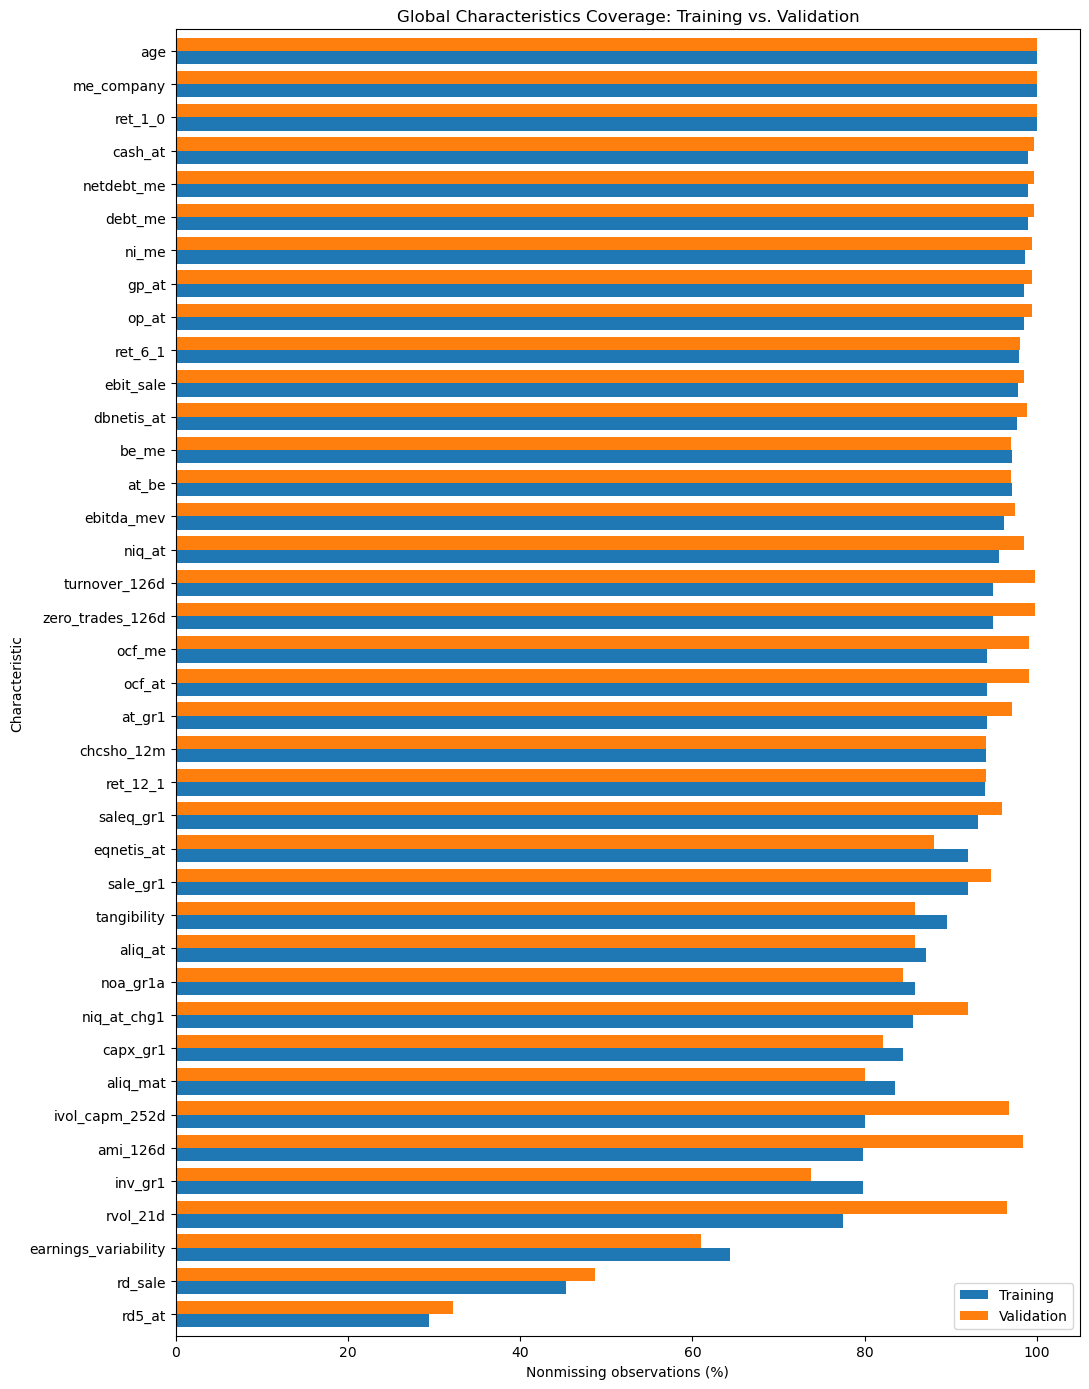

In [26]:
coverage_plot = global_coverage.sort_values(
    "training_nonmissing_pct"
)

ax = coverage_plot.set_index("feature")[
    [
        "training_nonmissing_pct",
        "validation_nonmissing_pct"
    ]
].plot.barh(
    figsize=(11, 14),
    width=0.8
)

ax.set_xlabel("Nonmissing observations (%)")
ax.set_ylabel("Characteristic")

ax.set_title(
    "Global Characteristics Coverage: "
    "Training vs. Validation"
)

ax.legend(["Training", "Validation"])

plt.tight_layout()
plt.savefig(figures_dir / "global_feature_coverage.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(ax.figure)

In [27]:
development_sample = df.loc[
    development_mask
    & df["baseline_eligible"],
    ["forecast_month"] + GLOBAL_FEATURES
]

development_periods = pd.cut(
    development_sample["forecast_month"].dt.year,
    bins=[1962, 1972, 1982, 1992, 1995, 2003],
    labels=[
        "1963-1972",
        "1973-1982",
        "1983-1992",
        "1993-1995",
        "1996-2003"
    ]
)

period_coverage = {}

for feature in GLOBAL_FEATURES:

    observed = (
        development_sample[feature]
        .replace([np.inf, -np.inf], np.nan)
        .notna()
    )

    period_coverage[feature] = (
        observed.groupby(
            development_periods,
            observed=True
        ).mean() * 100
    )

period_coverage = pd.DataFrame(
    period_coverage
).T

display(period_coverage.round(2))

del development_sample
gc.collect()

forecast_month,1963-1972,1973-1982,1983-1992,1993-1995,1996-2003
gp_at,98.360000,99.170000,98.280000,98.600000,99.430000
op_at,98.360000,99.170000,98.280000,98.610000,99.430000
niq_at,55.550000,93.900000,96.520000,96.460000,98.500000
ebit_sale,98.580000,99.140000,97.390000,97.560000,98.480000
ocf_at,85.160000,91.910000,94.190000,97.320000,99.090000
at_be,98.350000,98.910000,96.550000,96.560000,96.970000
debt_me,92.590000,99.420000,98.810000,98.980000,99.630000
netdebt_me,92.590000,99.420000,98.810000,98.980000,99.630000
cash_at,98.160000,99.350000,98.790000,98.960000,99.630000
aliq_at,83.100000,89.280000,87.260000,84.450000,85.840000


313

Inspect rank correlations using a fixed seed (42) and a training-only diagnostic subsample. Do not randomly split the modeling panel. Retain correlated features because they may contain incremental information at different horizons; regularization is a possible choice for teammates' expanded models, not an implemented model here.

In [28]:
correlation_sample = df.loc[
    baseline_train_mask,
    ALL_FEATURES
].sample(
    n=min(200_000, baseline_train_mask.sum()),
    random_state=42
)

correlation_sample = correlation_sample.replace(
    [np.inf, -np.inf],
    np.nan
)

correlation_matrix = correlation_sample.corr(
    method="spearman",
    min_periods=1000
)

chs_correlations = correlation_matrix.loc[
    GLOBAL_FEATURES,
    CHS_FEATURES
]

redundancy_summary = pd.DataFrame({
    "global_feature": GLOBAL_FEATURES,

    "closest_chs_feature":
        chs_correlations.abs().idxmax(axis=1).values,

    "max_absolute_correlation":
        chs_correlations.abs().max(axis=1).values
}).sort_values(
    "max_absolute_correlation",
    ascending=False
)

display(redundancy_summary)

,global_feature,closest_chs_feature,max_absolute_correlation
19,be_me,mb,0.973553
18,me_company,rsize,0.950971
26,rvol_21d,sigma,0.911965
27,ivol_capm_252d,sigma,0.907273
35,ami_126d,rsize,0.892327
6,debt_me,tlmta,0.870769
8,cash_at,cashmta,0.829065
2,niq_at,nimtaavg,0.778114
5,at_be,tlmta,0.753755
20,ni_me,nimtaavg,0.687169


## Verify NIMTAAVG convention

The initial quarterly-block diagnostic did not reproduce the supplied NIMTAAVG. Compare plausible weighting conventions on identical complete histories before deciding whether to retain the supplied feature.

In [29]:
history = pd.read_parquet(
    file_path,
    columns=[
        "permno",
        "month_end",
        "nimta",
        "nimtaavg"
    ]
)

history["month_end"] = pd.to_datetime(
    history["month_end"]
)

history = (
    history.loc[history["month_end"] < TRAIN_END]
    .sort_values(["permno", "month_end"])
    .reset_index(drop=True)
)

history["month_index"] = (
    history["month_end"].dt.year * 12
    + history["month_end"].dt.month
)

groups = history.groupby("permno", sort=False)

phi = 2 ** (-1 / 3)

monthly_weights = phi ** np.arange(12)
monthly_weights /= monthly_weights.sum()

quarter_weights = phi ** (3 * np.arange(4))
quarter_weights /= quarter_weights.sum()

methods = {
    "Quarterly lags 0, 3, 6, 9": dict(
        zip([0, 3, 6, 9], quarter_weights)
    ),

    "Quarterly lags 2, 5, 8, 11": dict(
        zip([2, 5, 8, 11], quarter_weights)
    ),

    "Monthly geometric weights": dict(
        zip(range(12), monthly_weights)
    ),

    "Quarterly block averages": dict(
        zip(range(12), np.repeat(quarter_weights / 3, 3))
    )
}

reconstructed = {
    name: np.zeros(len(history))
    for name in methods
}

valid = history["nimtaavg"].notna().to_numpy()

for lag in range(12):

    value = groups["nimta"].shift(lag)
    month = groups["month_index"].shift(lag)

    consecutive = (
        history["month_index"] - month
    ).eq(lag)

    valid &= (
        value.notna() & consecutive
    ).to_numpy()

    values = value.fillna(0).to_numpy()

    for name, method_weights in methods.items():
        if lag in method_weights:
            reconstructed[name] += (
                method_weights[lag] * values
            )

records = []

for name, values in reconstructed.items():

    error = np.abs(
        history.loc[valid, "nimtaavg"].to_numpy()
        - values[valid]
    )

    records.append({
        "method": name,
        "comparable_observations": len(error),
        "match_pct_1e6": np.mean(error <= 1e-6) * 100,
        "match_pct_1e4": np.mean(error <= 1e-4) * 100,
        "mean_absolute_error": error.mean(),
        "median_absolute_error": np.median(error),
        "max_absolute_error": error.max()
    })

nimta_methods = pd.DataFrame(records).sort_values(
    "mean_absolute_error"
)

display(nimta_methods)

del history, groups, reconstructed
gc.collect()

,method,comparable_observations,match_pct_1e6,match_pct_1e4,mean_absolute_error,median_absolute_error,max_absolute_error
2,Monthly geometric weights,869404,100.000000,100.000000,0.000000,0.000000,0.000000
3,Quarterly block averages,869404,2.925222,47.914318,0.000502,0.000110,0.428848
0,"Quarterly lags 0, 3, 6, 9",869404,0.817342,19.126551,0.002832,0.000593,3.177993
1,"Quarterly lags 2, 5, 8, 11",869404,0.645615,15.824059,0.003798,0.000818,4.395550


22

In the original run, monthly geometric weighting reproduced supplied NIMTAAVG within $10^{-6}$ for all 869,404 comparable rows; EXRETAVG also matched monthly geometric weighting for complete histories. Retain the supplied features and document the monthly-versus-quarterly NIMTAAVG deviation from CHS. The TA confirmed that missing monthly inputs are filled using the cross-sectional mean for the corresponding historical month; our complete-history checks do not independently reproduce those fills.

## Coverage screen

Keep additional features with at least 60% finite coverage on the initial baseline-eligible training sample. This outcome-independent threshold limits excessive imputation while preserving a broad economic library. It excludes `rd_sale` and `rd5_at` in the original run, leaving 37 additional features (45 total). Retain `tangibility` as an asset-structure proxy. Freeze this feature list for the main comparison; no test performance enters the screen.

In [30]:
MIN_COVERAGE = 60.0

coverage_lookup = global_coverage.set_index(
    "feature"
)["training_nonmissing_pct"]

SELECTED_GLOBAL_FEATURES = [
    feature
    for feature in GLOBAL_FEATURES
    if coverage_lookup[feature] >= MIN_COVERAGE
]

EXCLUDED_GLOBAL_FEATURES = [
    feature
    for feature in GLOBAL_FEATURES
    if feature not in SELECTED_GLOBAL_FEATURES
]

FINAL_FEATURES = (
    CHS_FEATURES + SELECTED_GLOBAL_FEATURES
)

FINAL_FEATURE_GROUPS = {
    group: [
        feature for feature in features
        if feature in SELECTED_GLOBAL_FEATURES
    ]
    for group, features in FEATURE_GROUPS.items()
}

print("CHS features:", len(CHS_FEATURES))

print(
    "Selected Global Characteristics:",
    len(SELECTED_GLOBAL_FEATURES)
)

print(
    "Total predictors:",
    len(FINAL_FEATURES)
)

print(
    "Excluded features:",
    EXCLUDED_GLOBAL_FEATURES
)

display(
    global_coverage.loc[
        global_coverage["feature"].isin(
            EXCLUDED_GLOBAL_FEATURES
        )
    ]
)

CHS features: 8
Selected Global Characteristics: 37
Total predictors: 45
Excluded features: ['rd_sale', 'rd5_at']


,feature,economic_group,training_nonmissing_pct,validation_nonmissing_pct,training_mean,training_std,training_median,training_unique_values
32,rd_sale,intangible_capital,45.320204,48.745121,0.822190,22.802418,0.020988,57747
33,rd5_at,intangible_capital,29.371031,32.194957,0.146173,0.263834,0.073060,27658


In [31]:
feature_manifest = pd.DataFrame([
    {
        "feature": feature,
        "source": "CHS",
        "economic_group": "baseline",
        "selected": True,
        "missing_value_policy": (
            "training_mean"
            if feature == "sigma"
            else "required"
        )
    }
    for feature in CHS_FEATURES
] + [
    {
        "feature": feature,
        "source": "Global Characteristics",
        "economic_group": feature_to_group[feature],
        "selected": feature in SELECTED_GLOBAL_FEATURES,
        "missing_value_policy": (
            "training_median"
            if feature in SELECTED_GLOBAL_FEATURES
            else "excluded"
        )
    }
    for feature in GLOBAL_FEATURES
])

feature_manifest["lower_winsorization_quantile"] = 0.05
feature_manifest["upper_winsorization_quantile"] = 0.95

display(feature_manifest)

,feature,source,economic_group,selected,missing_value_policy,lower_winsorization_quantile,upper_winsorization_quantile
0,nimtaavg,CHS,baseline,True,required,0.050000,0.950000
1,tlmta,CHS,baseline,True,required,0.050000,0.950000
2,exretavg,CHS,baseline,True,required,0.050000,0.950000
3,sigma,CHS,baseline,True,training_mean,0.050000,0.950000
4,rsize,CHS,baseline,True,required,0.050000,0.950000
5,cashmta,CHS,baseline,True,required,0.050000,0.950000
6,mb,CHS,baseline,True,required,0.050000,0.950000
7,price_log,CHS,baseline,True,required,0.050000,0.950000
8,gp_at,Global Characteristics,profitability,True,training_median,0.050000,0.950000
9,op_at,Global Characteristics,profitability,True,training_median,0.050000,0.950000


A separate Python file has been created for the GitHub repository with reusable winsorization and missing-value treatment.

The module contains two principal functions:

*fit_preprocessor()*: Estimate winsorization bounds and imputation parameters using the supplied training sample

*transform_features()*: Apply previously estimated parameters without learning anything from new observations

## Preprocessing choices

Treat infinities as missing and clip all selected predictors at the pooled 5th and 95th percentiles fitted on the eligible labeled estimation sample only. This follows the CHS outlier-control approach but avoids full-sample thresholds; PRICE retains the supplied $15 cap before our percentile clipping. After clipping, use the training mean for missing SIGMA and training medians for missing expanded characteristics (robust to skew). Required baseline features are not imputed. Do not add missingness indicators or scale the shared predictors; model-specific scaling can be fitted within training folds. `fit_preprocessor` estimates parameters, while `transform_features` applies them without learning from validation or test data.

For Global Characteristics, our training-median imputation is downstream of provider-specific construction and missing-value rules; the supplied local merge preserves missing values. For raw SIGMA, we deliberately use the training mean instead of the supplied same-month `sigma_fill`. The existing fitted parameters and feature manifest are unchanged.

In [32]:
import sys

src_dir = project_root / "src"

assert (src_dir / "preprocessing.py").exists()

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from preprocessing import (
    fit_preprocessor,
    transform_features
)

print("Preprocessing module imported successfully.")

Preprocessing module imported successfully.


In [33]:
baseline_train_mask = (
    train_mask
    & df["baseline_eligible"]
)

initial_params = fit_preprocessor(
    train=df.loc[
        baseline_train_mask,
        FINAL_FEATURES
    ],
    chs_features=CHS_FEATURES,
    global_features=SELECTED_GLOBAL_FEATURES,
    lower=0.05,
    upper=0.95
)

display(initial_params)

assert len(initial_params) == 45

assert initial_params.index.tolist() == FINAL_FEATURES

assert initial_params["training_rows"].eq(
    baseline_train_mask.sum()
).all()

print("Initial preprocessing parameters validated.")

,lower,upper,imputation,fill_value,training_nonmissing,training_rows
feature,,,,,,
nimtaavg,-0.049186,0.023974,required,NaN,1042054,1042054
tlmta,0.046153,0.920315,required,NaN,1042054,1042054
exretavg,-0.097040,0.069294,required,NaN,1042054,1042054
sigma,0.166089,1.309396,mean,0.523212,1022396,1042054
rsize,-13.433268,-6.623077,required,NaN,1042054,1042054
cashmta,0.002121,0.313580,required,NaN,1042054,1042054
mb,0.466340,5.299523,required,NaN,1042054,1042054
price_log,-0.547957,2.708050,required,NaN,1042054,1042054
gp_at,-0.010724,0.865385,median,0.303030,1026977,1042054


Initial preprocessing parameters validated.


In [34]:
baseline_validation_mask = (
    validation_mask
    & df["baseline_eligible"]
)

train_preview = df.loc[
    baseline_train_mask,
    FINAL_FEATURES
].head(1000)

validation_preview = df.loc[
    baseline_validation_mask,
    FINAL_FEATURES
].head(1000)

X_train_preview = transform_features(
    train_preview,
    initial_params
)

X_validation_preview = transform_features(
    validation_preview,
    initial_params
)

assert X_train_preview.shape == (1000, 45)
assert X_validation_preview.shape == (1000, 45)

assert not X_train_preview.isna().any().any()
assert not X_validation_preview.isna().any().any()

assert np.isfinite(
    X_train_preview.to_numpy()
).all()

assert np.isfinite(
    X_validation_preview.to_numpy()
).all()

for feature in FINAL_FEATURES:

    lower = initial_params.loc[feature, "lower"]
    upper = initial_params.loc[feature, "upper"]

    assert X_validation_preview[feature].between(
        lower, upper
    ).all()

print("All preprocessing integrity checks passed.")

display(X_train_preview.head())

All preprocessing integrity checks passed.


,nimtaavg,tlmta,exretavg,sigma,rsize,cashmta,mb,price_log,gp_at,op_at,niq_at,ebit_sale,ocf_at,at_be,debt_me,netdebt_me,cash_at,aliq_at,aliq_mat,at_gr1,sale_gr1,saleq_gr1,niq_at_chg1,capx_gr1,inv_gr1,noa_gr1a,me_company,be_me,ni_me,ocf_me,ebitda_mev,ret_1_0,ret_6_1,ret_12_1,rvol_21d,ivol_capm_252d,earnings_variability,chcsho_12m,eqnetis_at,dbnetis_at,tangibility,ami_126d,zero_trades_126d,turnover_126d,age
2,-0.007555,0.046153,-0.013215,0.836883,-11.536272,0.043949,5.299523,1.490091,-0.009722,-0.199267,0.009146,-0.716340,-0.371096,2.050936,0.036497,0.034660,0.041667,0.711745,0.573287,0.089242,0.103359,0.103178,-0.000134,0.103950,0.076751,0.051647,16.330000,0.713259,-0.031292,-0.028475,-0.022076,0.260159,0.025641,0.061405,0.025173,0.026631,0.353953,0.003480,0.097222,-0.246651,0.399542,0.394101,0.168002,0.001294,29.000000
3,-0.007761,0.046153,-0.029970,0.534192,-11.592437,0.047181,5.299523,1.386294,-0.009722,-0.199267,0.009146,-0.716340,-0.371096,2.050936,0.039283,0.037306,0.041667,0.711745,0.573287,0.089242,0.103359,0.103178,-0.000134,0.103950,0.076751,0.051647,15.172000,0.713259,-0.033680,-0.030649,-0.023701,-0.098592,0.025641,0.061405,0.025173,0.026631,0.353953,0.003480,0.097222,-0.246651,0.399542,0.394101,0.007350,0.000787,29.000000
4,-0.008460,0.046565,-0.089451,0.567309,-11.893012,0.060065,5.299523,1.134423,-0.010724,-0.199267,-0.091858,-0.716340,-0.371096,1.835994,0.028489,-0.034509,0.517902,0.711745,0.573287,0.089242,0.103359,-0.382131,-0.000134,0.103950,0.076751,0.051647,11.793859,0.116743,-0.048330,-0.044006,-0.037851,-0.210526,0.025641,0.061405,0.038862,0.026631,0.353953,0.003480,0.097222,-0.246651,0.757813,0.394101,0.007469,0.000763,29.000000
5,-0.015225,0.056750,-0.074943,0.420791,-11.911756,0.031751,5.299523,1.129384,-0.010724,-0.199267,-0.091858,-0.716340,-0.371096,1.835994,0.028633,-0.034684,0.517902,0.711745,0.573287,0.089242,0.103359,-0.382131,-0.000134,0.103950,0.076751,0.051647,11.734594,0.116743,-0.048574,-0.044228,-0.038049,-0.005025,0.025641,0.061405,0.025173,0.026631,0.353953,0.003480,0.097222,-0.246651,0.757813,0.394101,0.351713,0.000747,30.000000
6,-0.021293,0.061432,-0.064907,0.594901,-11.939331,0.034371,5.299523,1.045124,-0.010724,-0.199267,-0.091858,-0.716340,-0.371096,1.835994,0.031150,-0.037733,0.517902,0.711745,0.573287,0.089242,0.103359,-0.382131,-0.000134,0.103950,0.076751,0.051647,10.786344,0.116743,-0.052845,-0.048116,-0.041525,-0.080808,-0.292857,0.061405,0.047395,0.026631,0.353953,0.003480,0.097222,-0.246651,0.757813,5.850128,0.679694,0.000660,31.000000


## Preserve raw predictors

Export the untransformed 45-feature panel with eligibility and target metadata, plus the ordered manifest and initial preprocessing parameters. This allows teammates to refit transformations within rolling windows or test alternative missing-value policies rather than inherit a single permanently transformed panel.

In [35]:
METADATA_COLS = [
    "permno",
    "permco",
    "gvkey",
    "month_end",
    "feature_month",
    "forecast_month",
    "target",
    "labeled",
    "baseline_eligible"
]

export_cols = METADATA_COLS + FINAL_FEATURES

assert len(export_cols) == len(set(export_cols))

assert not df.duplicated(
    ["permno", "month_end"]
).any()

feature_panel_path = (
    processed_dir / "part_II_features.parquet"
)

df[export_cols].to_parquet(
    feature_panel_path,
    index=False,
    compression="snappy"
)

metadata = pq.ParquetFile(
    feature_panel_path
).metadata

print("Part II feature panel exported.")

print("Rows:", metadata.num_rows)
print("Columns:", metadata.num_columns)

print(
    "File size (GB):",
    round(feature_panel_path.stat().st_size / 1e9, 3)
)

print("Path:", feature_panel_path)

Part II feature panel exported.
Rows: 3416761
Columns: 54
File size (GB): 0.756
Path: /Users/tanirya/Desktop/UPenn/Wharton 7th Semester/FNCE 2370/Final Project/data/processed/part_II_features.parquet


In [36]:
feature_manifest.to_csv(
    tables_dir / "feature_manifest.csv",
    index=False
)

initial_params.to_csv(
    tables_dir / "preprocessing_params_initial.csv"
)

policy_comparison.to_csv(
    tables_dir / "missing_value_policy_comparison.csv",
    index=False
)

global_coverage.to_csv(
    tables_dir / "global_feature_coverage.csv",
    index=False
)

period_coverage.to_csv(
    tables_dir / "historical_feature_coverage.csv"
)

redundancy_summary.to_csv(
    tables_dir / "feature_redundancy.csv",
    index=False
)

nimta_methods.to_csv(
    tables_dir / "nimtaavg_validation.csv",
    index=False
)

group_means.to_csv(
    tables_dir / "chs_failure_group_means.csv"
)

group_medians.to_csv(
    tables_dir / "chs_failure_group_medians.csv"
)

print("Part II diagnostic tables exported successfully.")

# Export the numeric evidence behind the construction and missingness checks.
for filename, diagnostic in {
    "chs_training_feature_summary": feature_summary,
    "chs_missingness": missingness,
    "chs_unusual_values": unusual_values,
    "price_validation": price_validation,
    "exret_validation": exret_validation,
    "exretavg_validation": exretavg_validation,
    "nimtaavg_quarterly_block_validation": nimtaavg_validation,
    "accounting_ratio_validation": accounting_validation,
    "accounting_availability": accounting_diagnostics,
    "sigma_diagnostics": sigma_diagnostics,
    "sigma_fill_error_summary": fill_error.describe(),
    "exret_weights": weight_table,
}.items():
    if isinstance(diagnostic, pd.Series):
        diagnostic.to_csv(tables_dir / f"{filename}.csv", header=["value"])
    else:
        diagnostic.to_csv(tables_dir / f"{filename}.csv", index=filename != "exret_weights")
print("Additional validation tables and coverage figure saved.")

Part II diagnostic tables exported successfully.
Additional validation tables and coverage figure saved.
